# DATA UNDERSTANDING

### Import the Dependencies

In [1]:
# Image Processing Tools
import numpy as np
import cv2
from google.colab.patches import cv2_imshow
from PIL import Image
# Plot and Graph
import matplotlib.pyplot as plt
import seaborn as sns
# Deep Learning
import tensorflow as tf
from tensorflow import keras
from tensorflow.math import confusion_matrix

In [2]:
tf.random.set_seed(3)
sns.set_style('whitegrid')

### Import the Dataset

In [3]:
from keras.datasets import mnist

In [4]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

### Exploratory Data Analysis

In [5]:
type(X_train)

numpy.ndarray

In [6]:
X_train.shape, y_train.shape, X_test.shape, y_test.shape

((60000, 28, 28), (60000,), (10000, 28, 28), (10000,))

Training data = 60,000 images

Test data = 10,000 images

Images Dimension = 28x28

Grayscale Image = 1 channel

In [7]:
X_train[23]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0, 121, 254, 136,   0,   0,   0,   0,   0,
          0,   0],
       [  

In [8]:
X_train[23].shape

(28, 28)

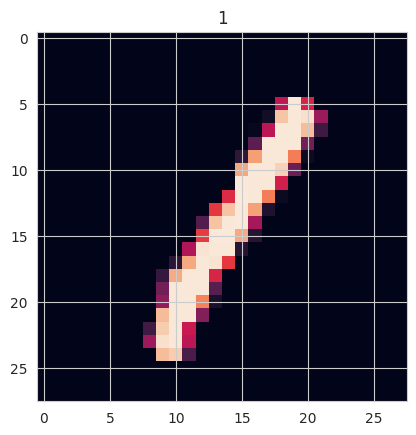

In [9]:
# Display the image
plt.imshow(X_train[23])
plt.title(y_train[23])
plt.show()

In [10]:
# Unique values in y_train
print(np.unique(y_train))
# Unique values in y_test
print(np.unique(y_test))

[0 1 2 3 4 5 6 7 8 9]
[0 1 2 3 4 5 6 7 8 9]


# DATA PREPARATION

### Feature Scaling

In [11]:
# Scaling the values
X_train = X_train/255
X_test = X_test/255

In [12]:
X_train[23]

array([[0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.    

# MODELING

### Build the NN

In [13]:
# Setting the layers
model = keras.Sequential([
    keras.layers.Flatten(input_shape=(28,28)),
    keras.layers.Dense(50, activation='relu'),
    keras.layers.Dense(50, activation='relu'),
    keras.layers.Dense(10, activation='sigmoid')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


### Compile the NN

In [14]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

### Train the NN

In [15]:
model.fit(X_train, y_train, epochs=10)

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - accuracy: 0.9111 - loss: 0.3098
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9569 - loss: 0.1449
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9684 - loss: 0.1062
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9751 - loss: 0.0834
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9791 - loss: 0.0688
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9822 - loss: 0.0580
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9854 - loss: 0.0492
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9871 - loss: 0.0418
Epoch 9/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9888 - loss: 0.0367
Epoch 10/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9896 - loss: 0.0318


# MODEL EVALUATION

In [16]:
# Accuracy
loss, accuracy = model.evaluate(X_test, y_test)
accuracy

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9658 - loss: 0.1286


0.9657999873161316

Test data accuracy = 96.8%

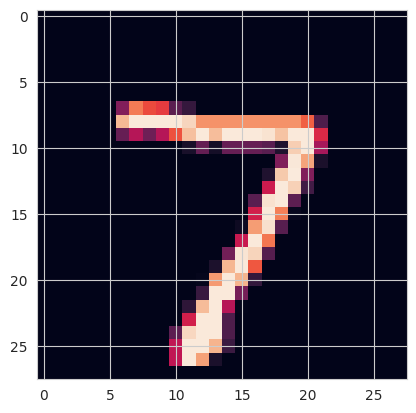

In [17]:
plt.imshow(X_test[0]);

In [18]:
print(y_test[0])

7


In [19]:
y_test.shape

(10000,)

### Make a Prediction

In [20]:
y_pred = model.predict(X_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [21]:
print(y_pred[0])

[6.3250482e-05 8.1087612e-03 5.0623538e-03 8.5689545e-01 2.1245563e-05
 2.1156116e-04 8.8115797e-07 9.9999332e-01 2.2964627e-02 9.5735139e-01]


In [22]:
y_pred.shape

(10000, 10)

In [23]:
# Convert the predict proba to class label
np.argmax(y_pred[0])

np.int64(7)

In [24]:
y_pred_label = [np.argmax(i) for i in y_pred]

In [25]:
y_pred_label[0]

np.int64(7)

In [26]:
print(y_pred)

[[6.3250482e-05 8.1087612e-03 5.0623538e-03 ... 9.9999332e-01
  2.2964627e-02 9.5735139e-01]
 [8.3137996e-10 1.4997566e-01 9.9999952e-01 ... 3.2929950e-11
  2.4889985e-07 4.5267718e-09]
 [1.0368124e-04 9.9943954e-01 1.9032417e-01 ... 2.0169494e-01
  2.8132543e-01 2.4373853e-03]
 ...
 [1.8601445e-07 1.8740390e-04 2.7689543e-06 ... 6.5329486e-01
  2.3710710e-01 9.8699051e-01]
 [5.5939138e-02 1.1951242e-05 9.1848938e-07 ... 1.9710130e-06
  9.9960065e-01 1.0832252e-04]
 [1.9292203e-05 2.2208103e-12 7.8496084e-02 ... 1.7265029e-09
  3.8954473e-05 6.0934471e-09]]


### Confusion Matrix

In [27]:
conf_mat = confusion_matrix(y_test, y_pred_label)

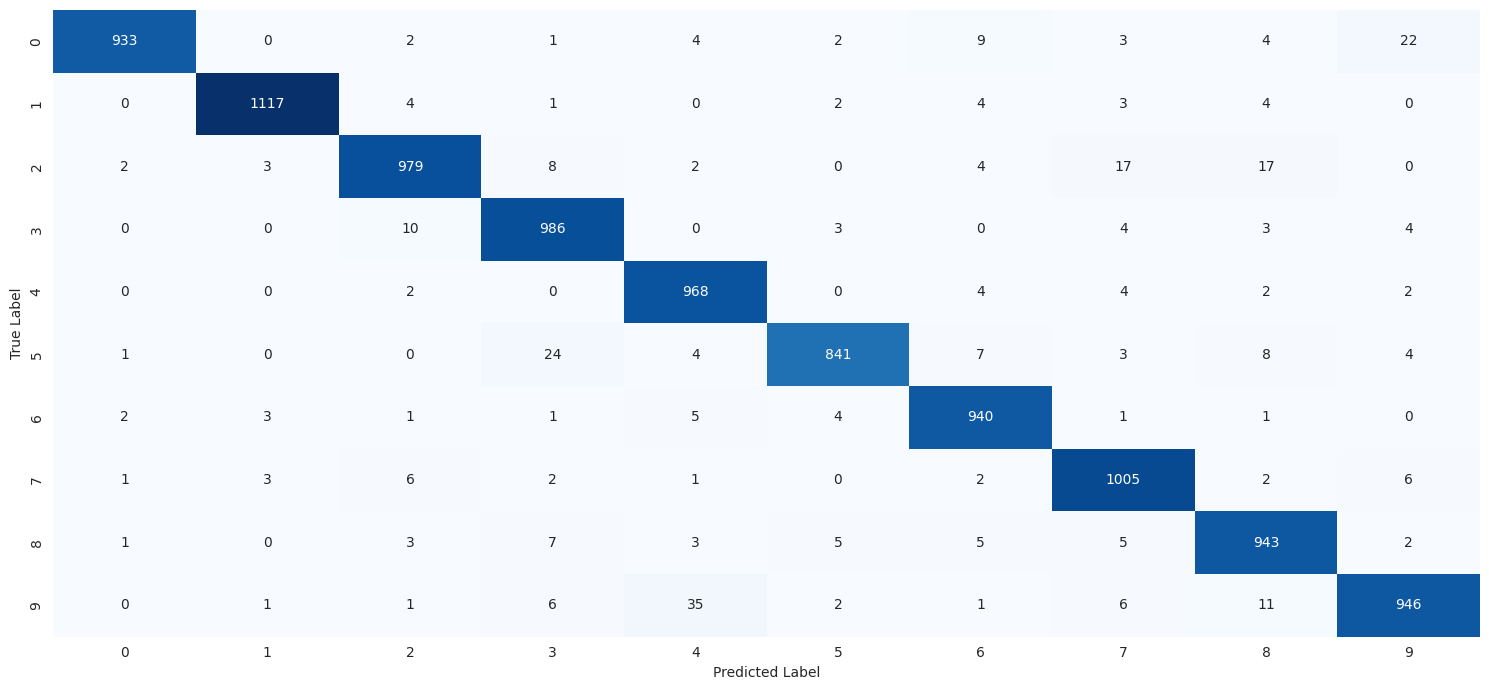

In [41]:
plt.figure(figsize=(15,7))
sns.heatmap(conf_mat, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.tight_layout()

# Predictive System

In [42]:
!wget 'https://imgs.search.brave.com/k1P2Rz_MUrS6XclJFya5jneoMrnh2iC8H59n-SpSv14/rs:fit:860:0:0:0/g:ce/aHR0cHM6Ly90My5m/dGNkbi5uZXQvanBn/LzE2Lzg4Lzc5Lzg0/LzM2MF9GXzE2ODg3/OTg0OTRfbDBhMWlF/dUlXMTJ5bkdnWmh6/aEExU2x5T0tMTEtK/Z1QuanBn'

--2026-10-17 17:32:37--  https://imgs.search.brave.com/k1P2Rz_MUrS6XclJFya5jneoMrnh2iC8H59n-SpSv14/rs:fit:860:0:0:0/g:ce/aHR0cHM6Ly90My5m/dGNkbi5uZXQvanBn/LzE2Lzg4Lzc5Lzg0/LzM2MF9GXzE2ODg3/OTg0OTRfbDBhMWlF/dUlXMTJ5bkdnWmh6/aEExU2x5T0tMTEtK/Z1QuanBn
Resolving imgs.search.brave.com (imgs.search.brave.com)... 13.249.182.50, 13.249.182.107, 13.249.182.60, ...
Connecting to imgs.search.brave.com (imgs.search.brave.com)|13.249.182.50|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 5984 (5.8K) [image/jpeg]
Saving to: ‘Z1QuanBn’

Z1QuanBn            100%[===================>]   5.84K  --.-KB/s    in 0s      

2026-10-17 17:32:38 (735 MB/s) - ‘Z1QuanBn’ saved [5984/5984]



In [43]:
input_image = cv2.imread('digit.jpg')

In [44]:
type(input_image)

numpy.ndarray

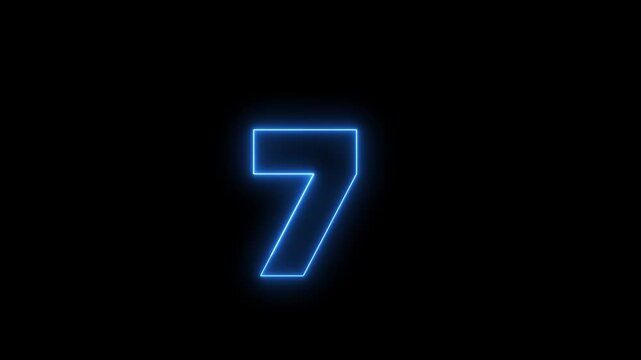

In [46]:
cv2_imshow(input_image)

In [47]:
input_image.shape

(360, 641, 3)

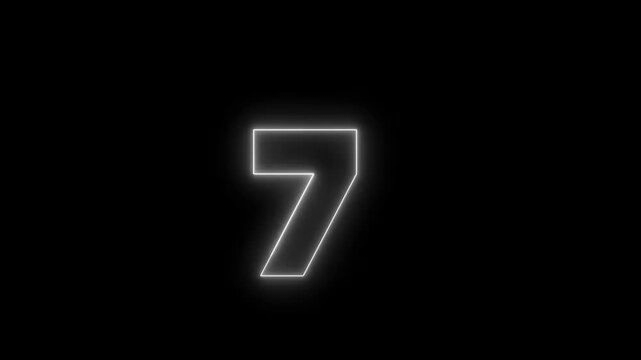

(360, 641)

In [50]:
grayscaled = cv2.cvtColor(input_image, cv2.COLOR_RGB2GRAY)
cv2_imshow(grayscaled)
grayscaled.shape

In [53]:
resized = cv2.resize(grayscaled, (28,28))
cv2_imshow(resized)
resized.shape

(28, 28)

In [54]:
resized = resized/255

In [56]:
reshaped_img = np.reshape(resized, [1,28,28])

In [ ]:
input_pred = model.predict(reshaped_img)